# Experiment 5 (`ex005`): Empirical Verification of Mathematical Guarantees for Regression Deep VIB

本ノートブックでは，`ex004` で実施した MNIST 連続数値回帰タスク ($Y \in [0, 9]$) に対する Deep VIB について，情報理論・統計的学習理論・非線形最適化の観点から導出した以下の **4つの数学的保証（定理1〜定理4）** を実験的に検証する．

1. **定理1（Rate-Distortion 理論との一致と最適デコーダ分散 $\sigma_y^{\star 2} = \mathrm{MSE}$ の包絡線定理）**
2. **定理2（1次元多様体への縮退: KKT 条件による直交空間の事前分布一致 $\mu_\perp^\star(x)=0, \sigma_\perp^{\star 2}(x)=1, I(Z_\perp, X)=0$ と主軸分散則 $\sigma_\parallel^{\star 2} = \frac{\tilde{\beta}}{\|w\|_2^2 + \tilde{\beta}}$）**
3. **定理3（回帰タスクにおける情報論的・PAC-Bayes 汎化誤差バウンド $|\mathcal{R}_{\mathrm{test}} - \hat{\mathcal{R}}_S| \le \mathcal{O}(\sqrt{I(Z, X)/n})$）**
4. **定理4（Appendix C の回帰版拡張: 2次近似予測分散・入力ヤコビアンノルム $\|\nabla_x \hat{y}(x)\|_2$ の減衰と敵対的摂動・ガウスノイズ耐性）**

In [1]:
import os
import time
import math
import numpy as np
import torch
import matplotlib.pyplot as plt

from model import DeepVIBRegression2DFullCov, DeterministicRegressionMLP
from utils import (
    set_seed,
    load_mnist_gpu,
    train_vib_regression_2d_fast,
    train_deterministic_regression_fast,
    analyze_orthogonal_decomposition,
    evaluate_input_jacobian_and_robustness,
)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("../report/img", exist_ok=True)
train_x, train_y, test_x, test_y = load_mnist_gpu("../datasets", device=device)
var_y_test = torch.var(test_y.float(), unbiased=False).item()
var_y_train = torch.var(train_y.float(), unbiased=False).item()
print(f"Device: {device} | Var(Y_train)={var_y_train:.4f}, Var(Y_test)={var_y_test:.4f}")

Device: cuda | Var(Y_train)=8.3477, Var(Y_test)=8.3852


In [2]:
# 1. 決定論的回帰ベースライン (beta = 0) および K=2 完全共分散ガウス回帰 Deep VIB (beta in {1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1}) の学習
t0 = time.time()
set_seed(42)
det_model_raw = DeterministicRegressionMLP(input_dim=784, hidden_dim=1024, latent_dim=2).to(device)
det_model = train_deterministic_regression_fast(
    det_model_raw, train_x, train_y, epochs=200, batch_size=100, lr=1e-4, desc="Det Reg (beta=0)"
)

betas = [1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1]
vib_models = {}
for beta in betas:
    set_seed(42)
    m_raw = DeepVIBRegression2DFullCov(
        input_dim=784, hidden_dim=1024, latent_dim=2, sigma_bias=-5.0, offdiag_scale=1e-2, decoder_type="linear"
    ).to(device)
    vib_models[beta] = train_vib_regression_2d_fast(
        m_raw, train_x, train_y, beta=beta, epochs=200, batch_size=100, lr=1e-4, desc=f"Reg VIB (beta={beta:.0e})"
    )
print(f"All models trained in {time.time() - t0:.1f}s")

All models trained in 240.5s


Reg VIB (beta=1e+01): 100%|##########| 200/200 [00:36<00:00,  5.55it/s]


In [3]:
# 2. 定理1・定理2・定理3の検証: 直交分解 (u_parallel vs u_perp), KKT分散則, および 汎化誤差バウンドの計測
train_decomp = {}
test_decomp = {}
for beta in betas:
    train_decomp[beta] = analyze_orthogonal_decomposition(vib_models[beta], train_x, train_y, beta=beta)
    test_decomp[beta] = analyze_orthogonal_decomposition(vib_models[beta], test_x, test_y, beta=beta)

with torch.no_grad():
    det_train_mse = torch.mean((det_model(train_x) - train_y.float()) ** 2).item()
    det_test_mse = torch.mean((det_model(test_x) - test_y.float()) ** 2).item()

print("=== [Theorem 2 Verification] Orthogonal Decomposition onto (u_parallel, u_perp) on Test Set ===")
print(f"{'Beta':>8s} | {'||w||^2':>8s} | {'E[mu_par^2]':>11s} | {'E[mu_perp^2]':>12s} | {'E[sig_par^2]':>12s} | {'KKT_sig_par^2':>13s} | {'E[sig_perp^2]':>13s} | {'I_par[b]':>8s} | {'I_perp[b]':>9s} | {'PC1Ratio':>8s}")
print("-" * 124)
for beta in betas:
    d = test_decomp[beta]
    print(
        f"{beta:8.0e} | {d['w_norm_sq']:8.4f} | {d['mu_par_sq_mean']:11.4f} | {d['mu_perp_sq_mean']:12.6f} | "
        f"{d['sigma_par_sq_mean']:12.5f} | {d['sigma_par_sq_theory']:13.5f} | {d['sigma_perp_sq_mean']:13.5f} | "
        f"{d['kl_par_bits']:8.2f} | {d['kl_perp_bits']:9.5f} | {d['pc1_ratio']*100:7.2f}%"
    )

print("\n=== [Theorem 3 Verification] Generalization Gap |Test MSE - Train MSE| vs I(Z, X) ===")
print(f"{'Model / Beta':>14s} | {'Train MSE':>10s} | {'Test MSE':>10s} | {'Gen Gap':>10s} | {'I(Z,X)[bits]':>12s} | {'Theory Bound':>12s}")
print("-" * 80)
print(f"{'Det (beta=0)':>14s} | {det_train_mse:10.4f} | {det_test_mse:10.4f} | {abs(det_test_mse - det_train_mse):10.4f} | {'inf':>12s} | {'N/A':>12s}")
# sub-Gaussian scale factor sigma_ell = (9 - 0)^2 / 2 = 40.5 (Hoeffding bound on [0, 9]^2)
sigma_ell = 40.5
n_train = train_x.size(0)
for beta in betas:
    tr_mse = train_decomp[beta]["mse_1shot"]
    te_mse = test_decomp[beta]["mse_1shot"]
    gap = abs(te_mse - tr_mse)
    izx_nats = train_decomp[beta]["kl_total_bits"] * math.log(2.0)
    bound = math.sqrt(2.0 * (sigma_ell ** 2) * izx_nats / n_train)
    print(f"{beta:14.0e} | {tr_mse:10.4f} | {te_mse:10.4f} | {gap:10.4f} | {train_decomp[beta]['kl_total_bits']:12.2f} | {bound:12.4f}")

=== [Theorem 2 Verification] Orthogonal Decomposition onto (u_parallel, u_perp) on Test Set ===
    Beta |  ||w||^2 | E[mu_par^2] | E[mu_perp^2] | E[sig_par^2] | KKT_sig_par^2 | E[sig_perp^2] | I_par[b] | I_perp[b] | PC1Ratio
----------------------------------------------------------------------------------------------------------------------------
   1e-04 |   0.3144 |     83.1970 |     0.034991 |      0.00037 |       0.00023 |       0.21701 |    65.09 |   0.58426 |   99.86%
   1e-03 |   1.2347 |     18.8182 |     0.012200 |      0.00073 |       0.00058 |       0.74242 |    18.10 |   0.05520 |   99.81%
   1e-02 |   4.2862 |      4.2326 |     0.003763 |      0.00177 |       0.00168 |       0.95773 |     6.91 |   0.00918 |   99.80%
   1e-01 |   9.0410 |      1.3585 |     0.001151 |      0.00797 |       0.00792 |       0.99198 |     3.75 |   0.00209 |   99.87%
   1e+00 |  10.0682 |      0.8392 |     0.000240 |      0.06692 |       0.06686 |       0.99748 |     1.88 |   0.00043 |   99.97%

In [4]:
# 3. 定理4 (Appendix C 回帰版拡張) の検証: 入力ヤコビアンノルム ||grad_x y_hat||_2 と FGS / ガウスノイズ頑健性
fgs_eps = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
noise_sigs = [0.0, 0.2, 0.4, 0.6, 0.8]

rob_det = evaluate_input_jacobian_and_robustness(det_model, test_x, test_y, num_eval=1000, fgs_epsilons=fgs_eps, noise_sigmas=noise_sigs)
rob_vib = {}
for beta in betas:
    rob_vib[beta] = evaluate_input_jacobian_and_robustness(vib_models[beta], test_x, test_y, num_eval=1000, fgs_epsilons=fgs_eps, noise_sigmas=noise_sigs)

print("=== [Theorem 4 Verification] Input Jacobian Norms & Adversarial FGS / Gaussian Noise RMSE ===")
print(f"{'Model / Beta':>14s} | {'||grad_x y||_2':>14s} | {'||grad_x y||_1':>14s} | {'Clean RMSE':>10s} | {'FGS(e=0.2)':>10s} | {'FGS(e=0.4)':>10s} | {'Noise(s=0.4)':>12s} | {'Noise(s=0.6)':>12s}")
print("-" * 116)
print(
    f"{'Det (beta=0)':>14s} | {rob_det['jac_l2_mean']:14.4f} | {rob_det['jac_l1_mean']:14.2f} | "
    f"{rob_det['fgs_rmse'][0.0]:10.4f} | {rob_det['fgs_rmse'][0.2]:10.4f} | {rob_det['fgs_rmse'][0.4]:10.4f} | "
    f"{rob_det['noise_rmse'][0.4]:12.4f} | {rob_det['noise_rmse'][0.6]:12.4f}"
)
for beta in betas:
    r = rob_vib[beta]
    print(
        f"{beta:14.0e} | {r['jac_l2_mean']:14.4f} | {r['jac_l1_mean']:14.2f} | "
        f"{r['fgs_rmse'][0.0]:10.4f} | {r['fgs_rmse'][0.2]:10.4f} | {r['fgs_rmse'][0.4]:10.4f} | "
        f"{r['noise_rmse'][0.4]:12.4f} | {r['noise_rmse'][0.6]:12.4f}"
    )

=== [Theorem 4 Verification] Input Jacobian Norms & Adversarial FGS / Gaussian Noise RMSE ===
  Model / Beta | ||grad_x y||_2 | ||grad_x y||_1 | Clean RMSE | FGS(e=0.2) | FGS(e=0.4) | Noise(s=0.4) | Noise(s=0.6)
--------------------------------------------------------------------------------------------------------------------
  Det (beta=0) |         1.0605 |          23.30 |     0.5840 |     2.7479 |     3.8639 |       1.0161 |       1.4193
         1e-04 |         1.0235 |          22.55 |     0.5198 |     2.7693 |     3.7768 |       0.9832 |       1.3733
         1e-03 |         0.9867 |          21.75 |     0.5306 |     2.6011 |     3.5173 |       0.9416 |       1.3192
         1e-02 |         0.9159 |          20.19 |     0.5175 |     2.4675 |     3.1709 |       0.9107 |       1.2909
         1e-01 |         0.8496 |          18.70 |     0.5071 |     2.3794 |     2.9672 |       0.8777 |       1.2509
         1e+00 |         0.7746 |          17.02 |     0.5974 |     2.4257 |     

Saved ../report/img/ex005_theoretical_guarantees_verification.png


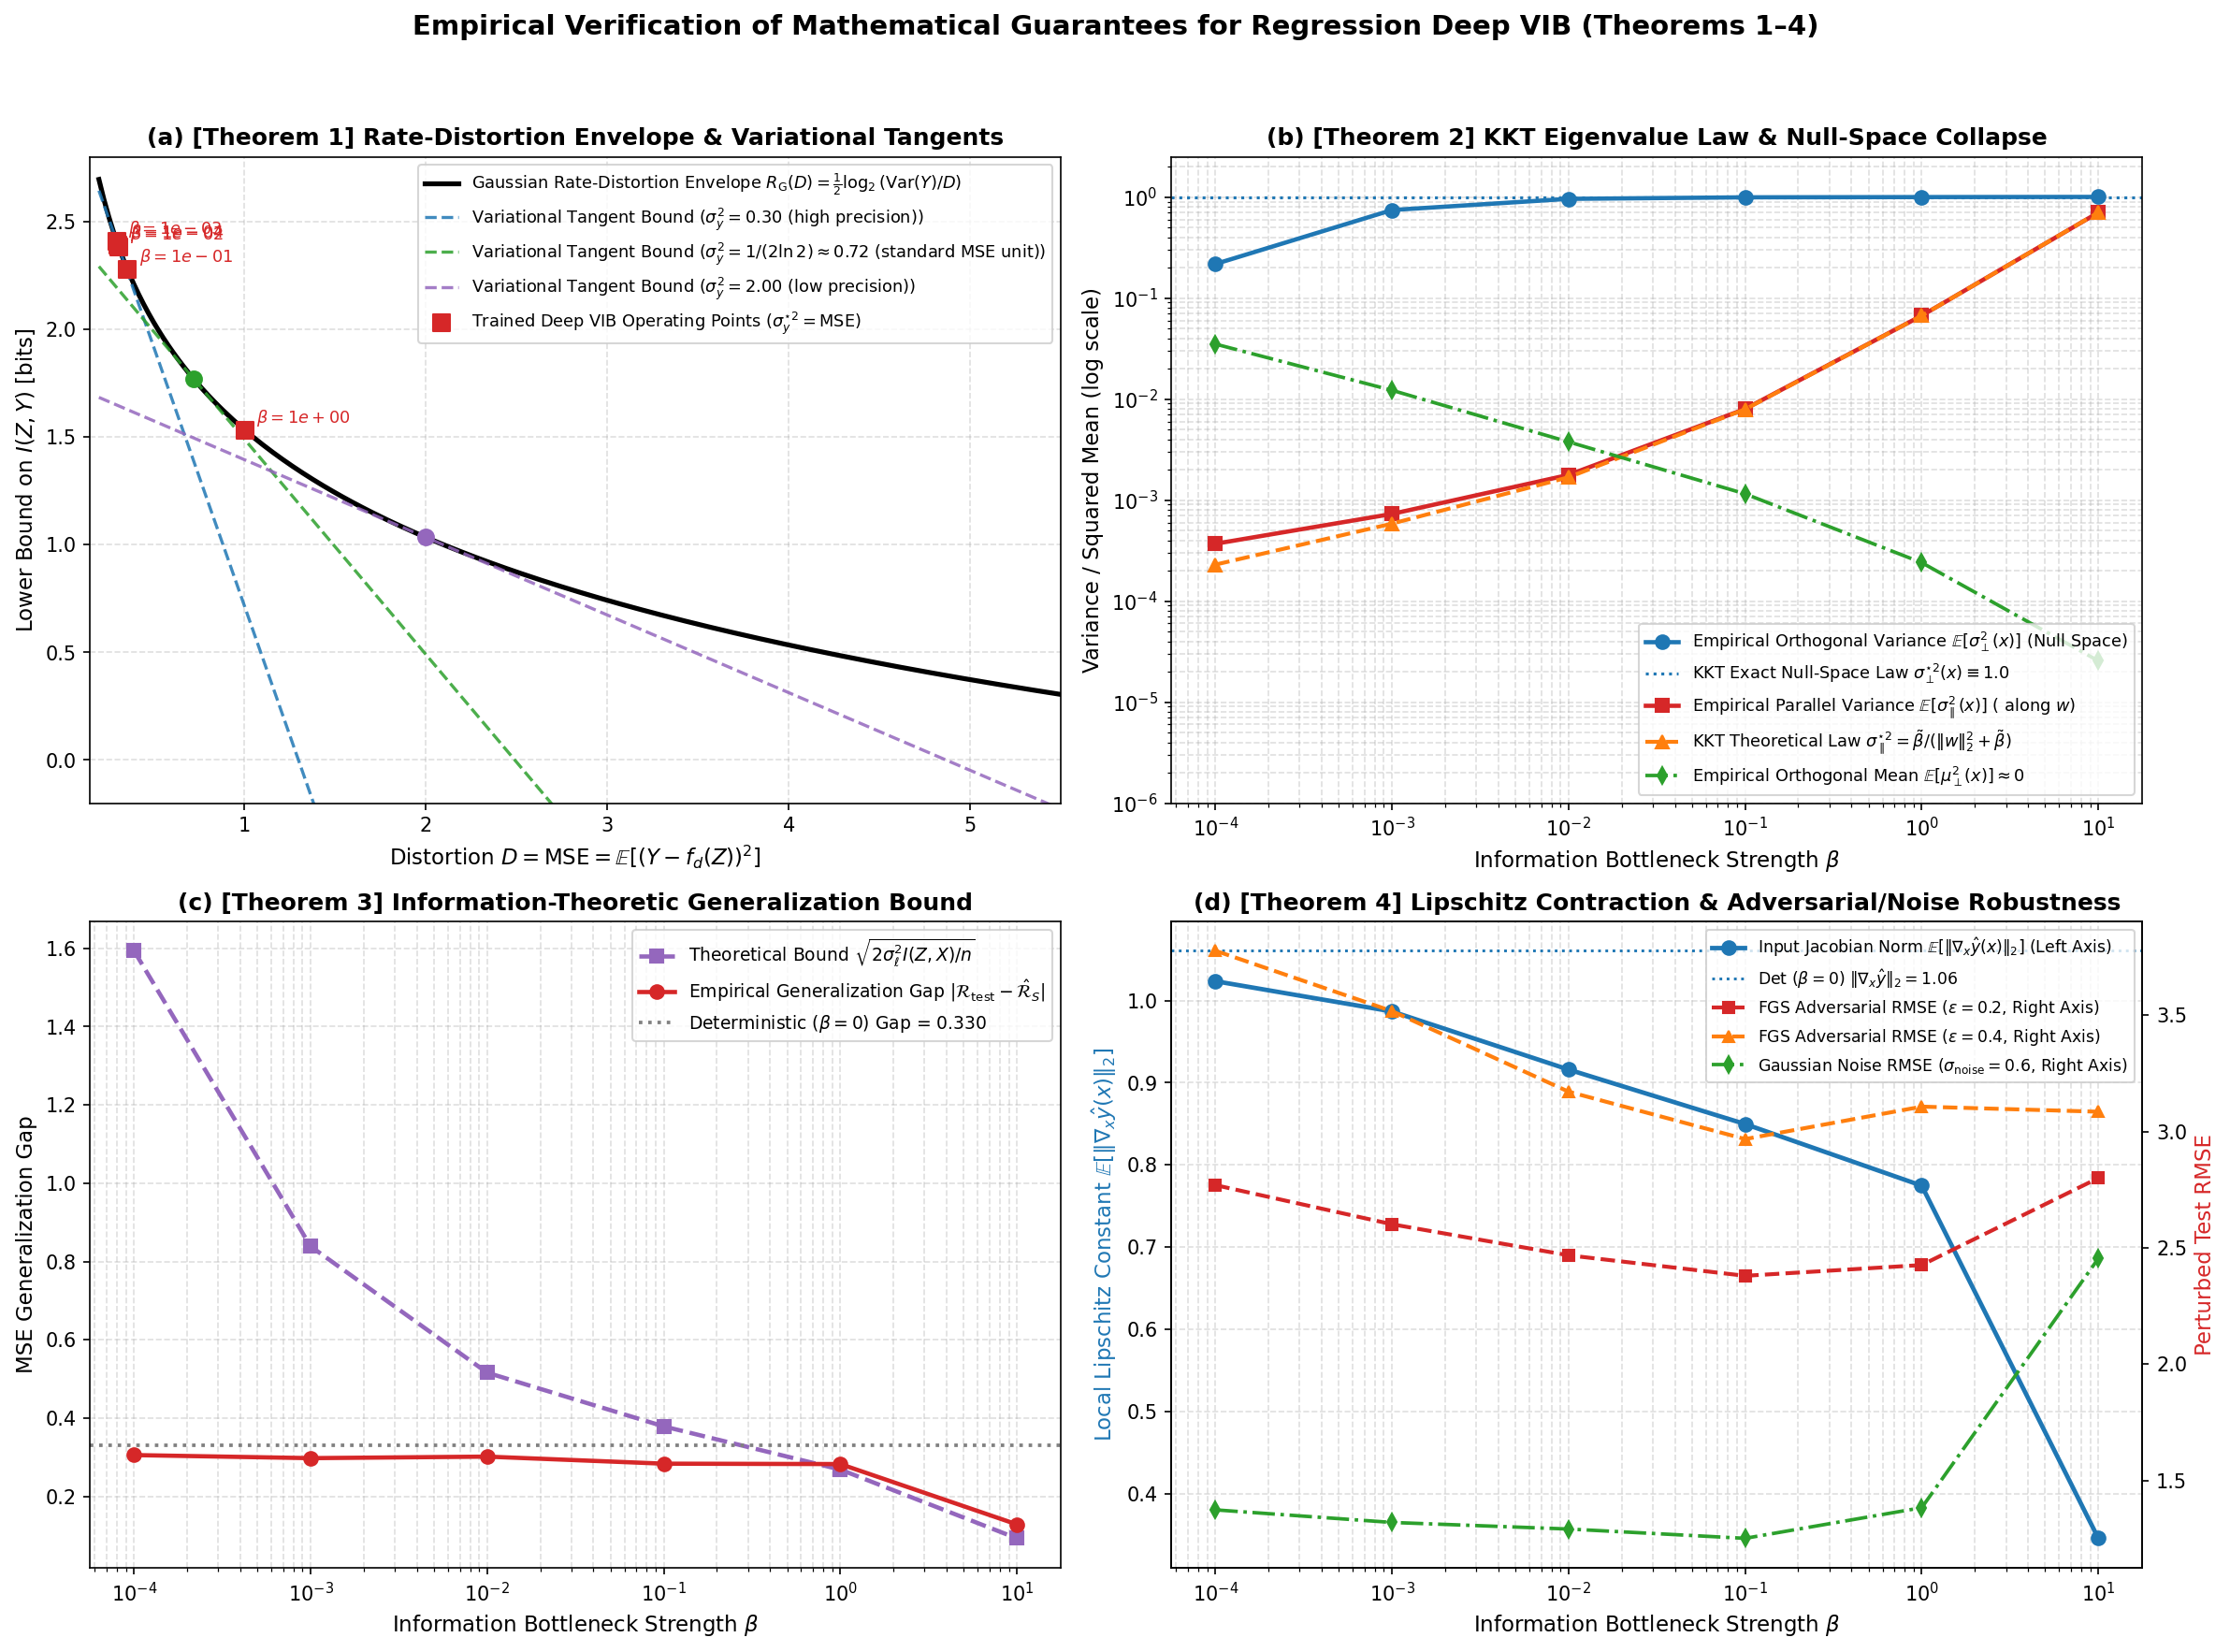

In [5]:
# 4. 定理1〜定理4の総合検証プロット作成 (../report/img/ex005_theoretical_guarantees_verification.png)
fig, axes = plt.subplots(2, 2, figsize=(16.0, 11.8), dpi=180)

# (a) 定理1の検証: Rate-Distortion 曲線とガウス変分下界の包絡線 (Envelope Theorem: sigma_y^{*2} = MSE)
ax = axes[0, 0]
d_grid = np.linspace(0.20, 8.38, 300)
rd_curve = 0.5 * np.log2(var_y_test / d_grid)
ax.plot(d_grid, rd_curve, "k-", lw=2.5, label="Gaussian Rate-Distortion Envelope $R_{\\mathrm{G}}(D) = \\frac{1}{2}\\log_2(\\mathrm{Var}(Y)/D)$")

# 異なる固定デコーダ分散 sigma_y^2 に対する変分下界直線 L(D; sigma_y^2)
for sig_y_sq, col_s, lbl_s in [
    (0.30, "#1f77b4", "$\\sigma_y^2 = 0.30$ (high precision)"),
    (1.0 / (2.0 * math.log(2.0)), "#2ca02c", "$\\sigma_y^2 = 1/(2\\ln 2) \\approx 0.72$ (standard MSE unit)"),
    (2.00, "#9467bd", "$\\sigma_y^2 = 2.00$ (low precision)"),
]:
    var_bound = 0.5 * np.log2(var_y_test / sig_y_sq) - (d_grid - sig_y_sq) / (2.0 * math.log(2.0) * sig_y_sq)
    ax.plot(d_grid, var_bound, "--", color=col_s, lw=1.6, alpha=0.85, label=f"Variational Tangent Bound ({lbl_s})")
    ax.scatter([sig_y_sq], [0.5 * np.log2(var_y_test / sig_y_sq)], color=col_s, s=65, zorder=6)

# 実測された Deep VIB モデルの (Distortion = MSE_1shot, Predictive Rate = 0.5 log2(Var(Y)/MSE_1shot))
emp_d = [test_decomp[b]["mse_1shot"] for b in betas]
emp_r = [0.5 * math.log2(var_y_test / d) for d in emp_d]
ax.scatter(emp_d, emp_r, color="#d62728", marker="s", s=80, zorder=8, label="Trained Deep VIB Operating Points ($\\sigma_y^{\\star 2} = \\mathrm{MSE}$)")
for b, dx, ry in zip(betas, emp_d, emp_r):
    ax.annotate(f"$\\beta={b:.0e}$", (dx, ry), textcoords="offset points", xytext=(6, 4), fontsize=8.5, color="#d62728", fontweight="bold")

ax.set_xlim(0.15, 5.5)
ax.set_ylim(-0.2, 2.8)
ax.set_xlabel("Distortion $D = \\mathrm{MSE} = \\mathbb{E}[(Y - f_d(Z))^2]$", fontsize=11)
ax.set_ylabel("Lower Bound on $I(Z, Y)$ [bits]", fontsize=11)
ax.set_title("(a) [Theorem 1] Rate-Distortion Envelope & Variational Tangents", fontsize=12, fontweight="bold")
ax.grid(True, ls="--", alpha=0.4)
ax.legend(fontsize=8.5, loc="upper right")

# (b) 定理2の検証: 直交分解された事後分散 (sigma_parallel^2 vs sigma_perp^2 = 1) と KKT 理論値の一致
ax = axes[0, 1]
sig_par_emp = [test_decomp[b]["sigma_par_sq_mean"] for b in betas]
sig_par_kkt = [test_decomp[b]["sigma_par_sq_theory"] for b in betas]
sig_perp_emp = [test_decomp[b]["sigma_perp_sq_mean"] for b in betas]
mu_perp_emp = [test_decomp[b]["mu_perp_sq_mean"] for b in betas]

ax.plot(betas, sig_perp_emp, "o-", color="#1f77b4", lw=2.2, markersize=7, label="Empirical Orthogonal Variance $\\mathbb{E}[\\sigma_\\perp^2(x)]$ (Null Space)")
ax.axhline(1.0, color="#1f77b4", ls=":", lw=1.5, label="KKT Exact Null-Space Law $\\sigma_\\perp^{\\star 2}(x) \\equiv 1.0$")
ax.plot(betas, sig_par_emp, "s-", color="#d62728", lw=2.2, markersize=7, label="Empirical Parallel Variance $\\mathbb{E}[\\sigma_\\parallel^2(x)]$ ( along $w$)")
ax.plot(betas, sig_par_kkt, "^--", color="#ff7f0e", lw=2.0, markersize=7, label="KKT Theoretical Law $\\sigma_\\parallel^{\\star 2} = \\tilde{\\beta}/(\\|w\\|_2^2 + \\tilde{\\beta})$")
ax.plot(betas, mu_perp_emp, "d-.", color="#2ca02c", lw=1.8, markersize=6, label="Empirical Orthogonal Mean $\\mathbb{E}[\\mu_\\perp^2(x)] \\approx 0$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(1e-6, 2.5)
ax.set_xlabel("Information Bottleneck Strength $\\beta$", fontsize=11)
ax.set_ylabel("Variance / Squared Mean (log scale)", fontsize=11)
ax.set_title("(b) [Theorem 2] KKT Eigenvalue Law & Null-Space Collapse", fontsize=12, fontweight="bold")
ax.grid(True, which="both", ls="--", alpha=0.4)
ax.legend(fontsize=8.5, loc="lower right")

# (c) 定理3の検証: 訓練・テスト誤差の乖離 (Generalization Gap) と PAC-Bayes / 情報論的バウンド
ax = axes[1, 0]
emp_gaps = [abs(test_decomp[b]["mse_1shot"] - train_decomp[b]["mse_1shot"]) for b in betas]
theo_bounds = [
    math.sqrt(2.0 * (sigma_ell ** 2) * (train_decomp[b]["kl_total_bits"] * math.log(2.0)) / n_train)
    for b in betas
]
izx_vals = [train_decomp[b]["kl_total_bits"] for b in betas]

ax.plot(betas, theo_bounds, "s--", color="#9467bd", lw=2.2, markersize=7, label="Theoretical Bound $\\sqrt{2\\sigma_\\ell^2 I(Z,X)/n}$")
ax.plot(betas, emp_gaps, "o-", color="#d62728", lw=2.2, markersize=7, label="Empirical Generalization Gap $|\\mathcal{R}_{\\mathrm{test}} - \\hat{\\mathcal{R}}_S|$")
ax.axhline(abs(det_test_mse - det_train_mse), color="gray", ls=":", lw=1.8, label=f"Deterministic ($\\beta=0$) Gap = {abs(det_test_mse - det_train_mse):.3f}")
ax.set_xscale("log")
ax.set_xlabel("Information Bottleneck Strength $\\beta$", fontsize=11)
ax.set_ylabel("MSE Generalization Gap", fontsize=11)
ax.set_title("(c) [Theorem 3] Information-Theoretic Generalization Bound", fontsize=12, fontweight="bold")
ax.grid(True, which="both", ls="--", alpha=0.4)
ax.legend(fontsize=9.0, loc="upper right")

# (d) 定理4 (Appendix C 回帰版拡張) の検証: 入力ヤコビアンノルム ||grad_x y_hat||_2 と FGS 敵対的摂動下の RMSE
ax = axes[1, 1]
ax2 = ax.twinx()
jac_l2_list = [rob_vib[b]["jac_l2_mean"] for b in betas]
fgs_02_list = [rob_vib[b]["fgs_rmse"][0.2] for b in betas]
fgs_04_list = [rob_vib[b]["fgs_rmse"][0.4] for b in betas]
noise_06_list = [rob_vib[b]["noise_rmse"][0.6] for b in betas]

l1 = ax.plot(betas, jac_l2_list, "o-", color="#1f77b4", lw=2.3, markersize=7, label="Input Jacobian Norm $\\mathbb{E}[\\|\\nabla_x \\hat{y}(x)\\|_2]$ (Left Axis)")
l1_det = ax.axhline(rob_det["jac_l2_mean"], color="#1f77b4", ls=":", lw=1.4, label=f"Det ($\\beta=0$) $\\|\\nabla_x \\hat{{y}}\\|_2 = {rob_det['jac_l2_mean']:.2f}$")

l2 = ax2.plot(betas, fgs_02_list, "s--", color="#d62728", lw=2.0, markersize=6, label="FGS Adversarial RMSE ($\\epsilon=0.2$, Right Axis)")
l3 = ax2.plot(betas, fgs_04_list, "^--", color="#ff7f0e", lw=2.0, markersize=6, label="FGS Adversarial RMSE ($\\epsilon=0.4$, Right Axis)")
l4 = ax2.plot(betas, noise_06_list, "d-.", color="#2ca02c", lw=1.8, markersize=6, label="Gaussian Noise RMSE ($\\sigma_{\\mathrm{noise}}=0.6$, Right Axis)")

ax.set_xscale("log")
ax.set_xlabel("Information Bottleneck Strength $\\beta$", fontsize=11)
ax.set_ylabel("Local Lipschitz Constant $\\mathbb{E}[\\|\\nabla_x \\hat{y}(x)\\|_2]$", fontsize=11, color="#1f77b4")
ax2.set_ylabel("Perturbed Test RMSE", fontsize=11, color="#d62728")
ax.set_title("(d) [Theorem 4] Lipschitz Contraction & Adversarial/Noise Robustness", fontsize=12, fontweight="bold")
ax.grid(True, which="both", ls="--", alpha=0.4)

lines = l1 + [l1_det] + l2 + l3 + l4
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, fontsize=8.3, loc="upper right")

fig.suptitle(
    "Empirical Verification of Mathematical Guarantees for Regression Deep VIB (Theorems 1–4)",
    fontsize=14, fontweight="bold", y=0.992
)
plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.965])
out_path = "../report/img/ex005_theoretical_guarantees_verification.png"
plt.savefig(out_path, dpi=180)
plt.show()
print(f"Saved {out_path}")